In [76]:
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.prompts import ChatPromptTemplate
from dotenv import load_dotenv
from langchain_core.output_parsers import StrOutputParser
from typing import TypedDict,Annotated,Literal
from langgraph.graph import StateGraph,START,END
from pydantic import BaseModel,Field

In [77]:
load_dotenv()

True

In [78]:
class ess_state(TypedDict):
    topic : str
    essay : str
    t : int
    scores : dict
    feedback : str
    avg_score : float

In [79]:
parser = StrOutputParser()

In [80]:
model = ChatGoogleGenerativeAI(model='gemini-2.5-flash')
model2 = ChatGoogleGenerativeAI(model='gemini-3.5-flash-lite')

In [81]:
prompt = ChatPromptTemplate([
    ('system','you are an expert essay writer and the user is going to provide you a topic and you have to write an essay for them'),
    ('human','{topic}')
])

In [82]:
gen_chain = prompt | model2 | parser

In [83]:
def gen_ess(state : ess_state):
    topic = state['topic']
    r = gen_chain.invoke({
        'topic' : topic
    })
    return {'essay' : r}

In [84]:
class EssayEvaluation(BaseModel):
    language_score: int = Field(
        ge=1,
        le=10,
        description="Score for grammar, vocabulary, spelling, punctuation, and readability."
    )

    reasoning_score: int = Field(
        ge=1,
        le=10,
        description="Score for logical flow, arguments, relevance, consistency, and supporting evidence."
    )

    explanation_score: int = Field(
        ge=1,
        le=10,
        description="Score for clarity, depth, examples, development of ideas, and explanation of the topic."
    )

    feedback: str = Field(
        description="Constructive feedback describing the essay's strengths, weaknesses, and actionable improvements."
    )

In [85]:
struct_model = model2.with_structured_output(EssayEvaluation)

In [86]:
prompt2 = ChatPromptTemplate([
    ("system", """You are an expert essay evaluator.

Evaluate the essay based on:
1. Language quality: grammar, vocabulary, spelling, and readability.
2. Reasoning quality: logical flow, arguments, relevance, and consistency.
3. Explanation quality: clarity, depth, examples, and development of ideas.

Assign integer scores from 1 to 10.
Provide specific, constructive feedback.
Evaluate the essay objectively against the given topic.
Do not generate a new essay.

Return the result using the provided structured output schema.
"""),
("human", """
Topic: {topic}

Essay:
{essay}
""")
])

In [87]:
eval_chain = prompt2 | struct_model

In [88]:
def eval_ess(state : ess_state):
    t = state['topic']
    r = state['essay']
    e = eval_chain.invoke({
    'topic' : t,
    'essay' : r
    })
    avg = (e.language_score + e.explanation_score + e.reasoning_score)/3
    score = {
        'reasoning_score' : e.reasoning_score,
        'explanation_score' : e.explanation_score,
        'language_score' : e.language_score
    }
    return {
        'scores' : score,
        'feedback' : e.feedback,
        'avg_score' : avg,
        't' : state['t']+1
    }

In [89]:
def check(state : ess_state)-> Literal['accept_ess',"regen_ess"]:
    if state['avg_score']>7 or state['t']>3:
        return 'accept_ess'
    else:
        return "regen_ess"

In [90]:
def accept_ess(state : ess_state):
    return state

In [91]:
prompt3 = ChatPromptTemplate([
    (
        "system",
        """You are an expert essay writer and editor.

Your task is to improve an existing essay using the evaluator's feedback.

Instructions:
1. Correct the weaknesses identified in the feedback.
2. Improve grammar, vocabulary, readability, and sentence structure.
3. Strengthen reasoning, arguments, examples, and logical flow.
4. Improve the introduction, body paragraphs, and conclusion where necessary.
5. Preserve the original topic, central argument, and useful ideas.
6. Retain existing strengths while correcting weaknesses.
7. Ignore feedback that is irrelevant or unsupported by the essay.
8. Do not invent facts, statistics, citations, or quotations.
9. Avoid unnecessary repetition and overly complicated language.
10. Generate the complete revised essay, not a summary.

Return only the revised essay.
"""
    ),
    (
        "human",
        """Original Topic:
{topic}

Previous Essay:
{previous_essay}

Evaluator's Feedback:
{feedback}

Write an improved version of the essay using the feedback above."""
    )
])

In [92]:
regen_chain = prompt3 | model | parser

In [93]:
def regen_ess(state : ess_state):
    t = state['topic']
    f = state['feedback']
    e = state['essay']
    reg = regen_chain.invoke({
    'topic' : t,
    'previous_essay' : e,
    'feedback' : f
    })
    return {'essay' : reg}

In [94]:
graph = StateGraph(ess_state)

In [95]:
graph.add_node('gen_ess',gen_ess)
graph.add_node('eval_ess',eval_ess)
graph.add_node('accept_ess',accept_ess)
graph.add_node('regen_ess',regen_ess)

In [96]:
graph.add_edge(START,'gen_ess')
graph.add_edge('gen_ess','eval_ess')
graph.add_conditional_edges('eval_ess',check)
graph.add_edge('accept_ess',END)
graph.add_edge('regen_ess','eval_ess')

In [97]:
wk = graph.compile()

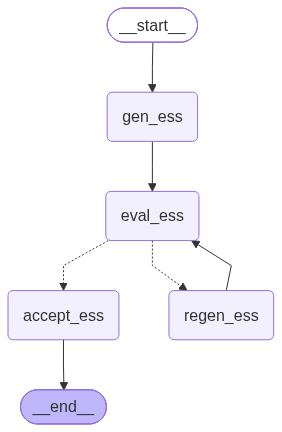

In [98]:
wk

In [99]:
initial = {
    'topic' : 'indian politics',
    't' : 0
}

In [100]:
final = wk.invoke(initial)

In [101]:
print(final)

{'topic': 'indian politics', 'essay': '**Title:** The Kaleidoscope of Democracy: Evolution, Dynamics, and Challenges in Indian Politics\n\nIndian politics is a vast, intricate, and endlessly fascinating kaleidoscope. As the world’s largest democracy, India’s political landscape is defined by its sheer scale, cultural diversity, and the relentless ambition of its electorate. Since gaining independence in 1947, India has transitioned from a one-party dominant state to a vibrant, highly competitive multiparty democracy. Understanding Indian politics requires looking beyond the headlines to examine the historical foundations, the evolving social dynamics, and the contemporary challenges that shape the destiny of over 1.4 billion people.\n\nTo understand modern Indian politics, one must look at its foundational era under the leadership of Jawaharlal Nehru. For the first three decades post-independence, the Indian National Congress (INC) held an almost unchallenged monopoly on power, a pheno